# Churn EDA — Verified Analysis

**Status: VERIFIED** — every claim reproduces from raw data via `scripts/verify_findings.py`.

Sources:
- `data/customers.csv`
- `data/transactions.db` (SQLite, table `transactions`)
- `data/transactions_monthly_agg.parquet`

Key references: `EDA_FINDINGS.md`, `DATA_ISSUES.md`, `MODEL_RECOMMENDATION.md`.

In [1]:
import pandas as pd
import sqlite3
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, chi2_contingency
import warnings
warnings.filterwarnings("ignore")

plt.style.use("seaborn-v0_8-whitegrid")
print("Libraries loaded.")

Libraries loaded.


## 1. Load all three sources

In [2]:
customers = pd.read_csv("data/customers.csv", parse_dates=["signup_date"])
print(f"customers.csv: {len(customers)} rows x {len(customers.columns)} cols")
print(f"Columns: {customers.columns.tolist()}")
customers.head(3)

customers.csv: 1500 rows x 5 cols
Columns: ['customer_id', 'signup_date', 'acquisition_channel', 'region', 'churned']


,customer_id,signup_date,acquisition_channel,region,churned
0,1,2026-04-16,organic,east,1
1,2,2024-08-28,organic,east,0
2,3,2024-12-10,organic,west,1


In [3]:
conn = sqlite3.connect("data/transactions.db")
txns = pd.read_sql("SELECT * FROM transactions", conn, parse_dates=["txn_timestamp"])
conn.close()
print(f"transactions.db: {len(txns)} rows x {len(txns.columns)} cols")
print(f"Columns: {txns.columns.tolist()}")
txns.head(3)

transactions.db: 11742 rows x 6 cols


Columns: ['customer_id', 'txn_timestamp', 'category', 'channel', 'amount', 'is_returned']


,customer_id,txn_timestamp,category,channel,amount,is_returned
0,2,2024-09-04 21:56:57.516326572,sports,web,80.12,0
1,2,2024-10-04 13:33:51.471903148,beauty,mobile_app,54.59,0
2,2,2024-10-07 01:05:16.340318820,electronics,web,185.28,0


In [4]:
monthly_agg = pd.read_parquet("data/transactions_monthly_agg.parquet")
monthly_agg["txn_month"] = pd.to_datetime(monthly_agg["txn_month"])
print(f"transactions_monthly_agg.parquet: {len(monthly_agg)} rows x {len(monthly_agg.columns)} cols")
print(f"Columns: {monthly_agg.columns.tolist()}")
monthly_agg.head(3)

transactions_monthly_agg.parquet: 8086 rows x 5 cols
Columns: ['customer_id', 'txn_month', 'txn_count', 'total_amount', 'return_count']


,customer_id,txn_month,txn_count,total_amount,return_count
0,2,2024-09-01,1,80.12,0
1,2,2024-10-01,4,298.21,0
2,2,2024-11-01,1,11.15,0


## 2. Schema, missingness, and zero-activity population

In [5]:
print("=== Missingness check ===")
for name, df in [("Customers", customers), ("Transactions", txns), ("Monthly Agg", monthly_agg)]:
    nulls = df.isna().sum().sum()
    print(f"  {name}: {nulls} nulls across all columns")

=== Missingness check ===
  Customers: 0 nulls across all columns
  Transactions: 0 nulls across all columns
  Monthly Agg: 0 nulls across all columns


In [6]:
# Zero-activity customers
active_ids = set(txns["customer_id"].unique())
all_ids = set(customers["customer_id"])
zero_activity = sorted(all_ids - active_ids)
print(f"Total customers: {len(all_ids)}")
print(f"Customers with >= 1 transaction: {len(active_ids)}")
print(f"Zero-activity customers: {len(zero_activity)}")

za = customers[customers["customer_id"].isin(zero_activity)]
print(f"Zero-activity with churned=1: {za['churned'].sum()}/{len(za)}")

Total customers: 1500
Customers with >= 1 transaction: 1419
Zero-activity customers: 81
Zero-activity with churned=1: 81/81


## 3. Distribution shape — transaction amount

In [7]:
amt = txns["amount"]
print("=== Transaction amount distribution ===")
print(f"Count: {len(amt)}")
print(f"Mean:  ${amt.mean():.2f}")
print(f"Median: ${amt.median():.2f}")
print(f"Std:   ${amt.std():.2f}")
print(f"Min:   ${amt.min():.2f}")
print(f"Q1:    ${amt.quantile(0.25):.2f}")
print(f"Q3:    ${amt.quantile(0.75):.2f}")
print(f"Max:   ${amt.max():.2f}")
print(f"Skewness: {amt.skew():.4f}")

q1, q3 = amt.quantile(0.25), amt.quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5*iqr
lower = q1 - 1.5*iqr
outliers = amt[(amt < lower) | (amt > upper)]
print(f"\n1.5xIQR outlier rule:")
print(f"  Lower bound: ${lower:.2f}")
print(f"  Upper bound: ${upper:.2f}")
print(f"  Outliers: {len(outliers)} ({len(outliers)/len(amt)*100:.1f}%)")
print(f"  All above upper bound: {(amt > upper).sum()}/{len(outliers)}")

=== Transaction amount distribution ===
Count: 11742
Mean:  $49.72
Median: $33.82
Std:   $55.24
Min:   $3.00
Q1:    $18.36
Q3:    $61.39
Max:   $1684.21
Skewness: 6.1066

1.5xIQR outlier rule:
  Lower bound: $-46.18
  Upper bound: $125.93
  Outliers: 783 (6.7%)
  All above upper bound: 783/783


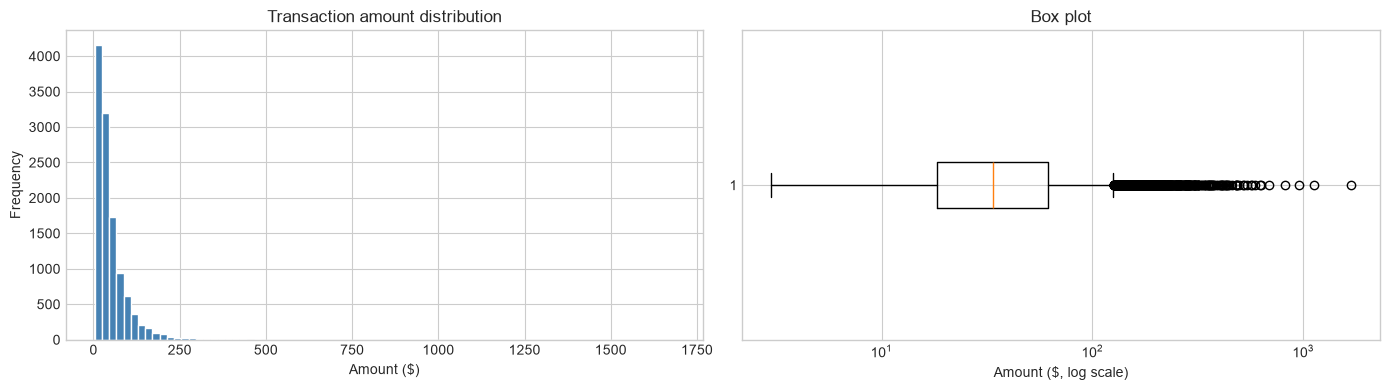

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(amt, bins=80, edgecolor="white", color="steelblue")
axes[0].set_title("Transaction amount distribution")
axes[0].set_xlabel("Amount ($)")
axes[0].set_ylabel("Frequency")

axes[1].boxplot(amt, vert=False)
axes[1].set_title("Box plot")
axes[1].set_xscale("log")
axes[1].set_xlabel("Amount ($, log scale)")
plt.tight_layout()
plt.show()

## 4. Churn rate breakdowns

In [9]:
print("=== Overall churn rate ===")
churned = customers["churned"].sum()
total = len(customers)
print(f"Churned: {churned}/{total} = {churned/total*100:.2f}%")

active_cust = customers[customers["customer_id"].isin(active_ids)]
active_ch = active_cust["churned"].sum()
active_total = len(active_cust)
print(f"\nAmong customers with at least one transaction:")
print(f"Churned: {active_ch}/{active_total} = {active_ch/active_total*100:.2f}%")

=== Overall churn rate ===
Churned: 202/1500 = 13.47%

Among customers with at least one transaction:
Churned: 121/1419 = 8.53%


In [10]:
print("=== Churn by acquisition channel ===")
print(customers.groupby("acquisition_channel")["churned"].agg(["count", "sum", "mean"]).assign(rate=lambda x: x["mean"]*100).to_string())
print("\n=== Churn by region ===")
print(customers.groupby("region")["churned"].agg(["count", "sum", "mean"]).assign(rate=lambda x: x["mean"]*100).to_string())

=== Churn by acquisition channel ===
                     count  sum      mean       rate
acquisition_channel                                 
organic                609   93  0.152709  15.270936
paid_search            431   44  0.102088  10.208817
referral               295   41  0.138983  13.898305
social                 165   24  0.145455  14.545455

=== Churn by region ===
        count  sum      mean       rate
region                                 
east      385   63  0.163636  16.363636
north     381   47  0.123360  12.335958
south     354   45  0.127119  12.711864
west      380   47  0.123684  12.368421


## 5. Hypothesis tests

In [11]:
from scipy.stats import chi2_contingency, mannwhitneyu

def cramers_v(table):
    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()
    k = min(table.shape)
    return np.sqrt(chi2 / n / (k - 1)) if n > 0 and k > 1 else 0.0

def rank_biserial(u, n1, n2):
    return 1 - (2 * u) / (n1 * n2)

print("--- Acquisition channel vs churn ---")
table = pd.crosstab(customers["acquisition_channel"], customers["churned"])
chi2, p, dof, exp = chi2_contingency(table)
cv = cramers_v(table)
print(f"Chi-square: chi2={chi2:.4f}, p={p:.4f}, Cramer's V={cv:.4f}")
print(f"Verdict: {'Significant' if p < 0.05 else 'Not significant'} at alpha=0.05")
print("Leakage: Not tainted (static attribute)")

print("\n--- Region vs churn ---")
table = pd.crosstab(customers["region"], customers["churned"])
chi2, p, dof, exp = chi2_contingency(table)
cv = cramers_v(table)
print(f"Chi-square: chi2={chi2:.4f}, p={p:.4f}, Cramer's V={cv:.4f}")
print(f"Verdict: {'Significant' if p < 0.05 else 'Not significant'} at alpha=0.05")
print("Leakage: Not tainted (static attribute)")

--- Acquisition channel vs churn ---
Chi-square: chi2=5.8387, p=0.1197, Cramer's V=0.0624
Verdict: Not significant at alpha=0.05
Leakage: Not tainted (static attribute)

--- Region vs churn ---
Chi-square: chi2=3.7571, p=0.2889, Cramer's V=0.0500
Verdict: Not significant at alpha=0.05
Leakage: Not tainted (static attribute)


In [12]:
# Customer-level monetary analysis
cust_amt = txns.groupby("customer_id")["amount"].sum().reset_index()
cust_amt.columns = ["customer_id", "total_amount"]
merged_mon = customers[["customer_id", "churned"]].merge(cust_amt, on="customer_id", how="left")
merged_mon["total_amount"] = merged_mon["total_amount"].fillna(0)

c_vals = merged_mon[merged_mon["churned"]==1]["total_amount"]
nc_vals = merged_mon[merged_mon["churned"]==0]["total_amount"]
u_stat, p_val = mannwhitneyu(c_vals, nc_vals, alternative="two-sided")
rb = rank_biserial(u_stat, len(c_vals), len(nc_vals))
print("--- Total amount vs churn ---")
print(f"Mann-Whitney U: U={u_stat:.1f}, p={p_val:.2e}")
print(f"Rank-biserial correlation: {rb:.4f}")
print(f"Median churned: ${c_vals.median():.2f}")
print(f"Median non-churned: ${nc_vals.median():.2f}")

print("\n--- Return rate vs churn ---")
cust_ret = txns.groupby("customer_id").agg(total_txns=("is_returned", "count"), return_count=("is_returned", "sum")).reset_index()
cust_ret["return_rate"] = cust_ret["return_count"] / cust_ret["total_txns"]
merged_ret = customers[["customer_id", "churned"]].merge(cust_ret, on="customer_id", how="left")
merged_ret["return_rate"] = merged_ret["return_rate"].fillna(0)
rc_vals = merged_ret[merged_ret["churned"]==1]["return_rate"]
r_nc_vals = merged_ret[merged_ret["churned"]==0]["return_rate"]
u2, p2 = mannwhitneyu(rc_vals, r_nc_vals, alternative="two-sided")
rb2 = rank_biserial(u2, len(rc_vals), len(r_nc_vals))
print(f"Mann-Whitney U: U={u2:.1f}, p={p2:.2e}")
print(f"Rank-biserial correlation: {rb2:.4f}")

--- Total amount vs churn ---
Mann-Whitney U: U=61626.5, p=7.17e-34
Rank-biserial correlation: 0.5299
Median churned: $71.12
Median non-churned: $364.38

--- Return rate vs churn ---
Mann-Whitney U: U=110279.0, p=9.28e-06
Rank-biserial correlation: 0.1588


In [13]:
# Days since last transaction — diagnostic only
asof = txns["txn_timestamp"].max()
print(f"As-of date: {asof}")

last_txn = txns.groupby("customer_id")["txn_timestamp"].max().reset_index()
last_txn["days_since"] = (asof - last_txn["txn_timestamp"]).dt.days
merged_dsl = customers[["customer_id", "churned"]].merge(last_txn[["customer_id", "days_since"]], on="customer_id", how="left")

nc = merged_dsl[merged_dsl["churned"]==0]["days_since"].dropna()
ac = merged_dsl[merged_dsl["churned"]==1]["days_since"].dropna()
print(f"\nNon-churned: n={len(nc)}, min={nc.min():.0f}d, max={nc.max():.0f}d, mean={nc.mean():.1f}d")
print(f"Churned (active): n={len(ac)}, min={ac.min():.0f}d, max={ac.max():.0f}d, mean={ac.mean():.1f}d")
print(f"\nWARNING: Complete separation by construction.")
print("The churn label = no purchase in trailing 90 days.")
print("This variable = days since last txn relative to same as-of date.")
print("They are the same thing. This is LEAKAGE, not prediction.")

As-of date: 2026-07-31 23:50:29.001075447



Non-churned: n=1298, min=0d, max=90d, mean=28.6d
Churned (active): n=121, min=91d, max=365d, mean=132.5d

The churn label = no purchase in trailing 90 days.
This variable = days since last txn relative to same as-of date.
They are the same thing. This is LEAKAGE, not prediction.


## 6. Monthly transaction-volume trend

In [14]:
txns["txn_month"] = txns["txn_timestamp"].dt.to_period("M").dt.to_timestamp()
monthly = txns.groupby("txn_month").agg(
    txn_count=("amount", "count"),
    total_amount=("amount", "sum"),
    unique_customers=("customer_id", "nunique")
).reset_index().sort_values("txn_month")

print(f"Period: {monthly.iloc[0]['txn_month'].strftime('%Y-%m')} to {monthly.iloc[-1]['txn_month'].strftime('%Y-%m')}")
print(f"Months: {len(monthly)}")
first_txn = monthly.iloc[0]["txn_count"]
last_txn = monthly.iloc[-1]["txn_count"]
print(f"Trend: {first_txn} -> {last_txn} transactions (~{last_txn/first_txn:.0f}x)")
print(f"Amount: ${monthly.iloc[0]['total_amount']:.2f} -> ${monthly.iloc[-1]['total_amount']:.2f}")
print(f"Customers: {monthly.iloc[0]['unique_customers']} -> {monthly.iloc[-1]['unique_customers']}")
print("\nConclusion: Strong upward trend — non-stationarity is real. Time-based split recommended.")

Period: 2024-02 to 2026-07
Months: 30
Trend: 1 -> 1231 transactions (~1231x)
Amount: $25.03 -> $62084.62
Customers: 1 -> 787

Conclusion: Strong upward trend — non-stationarity is real. Time-based split recommended.


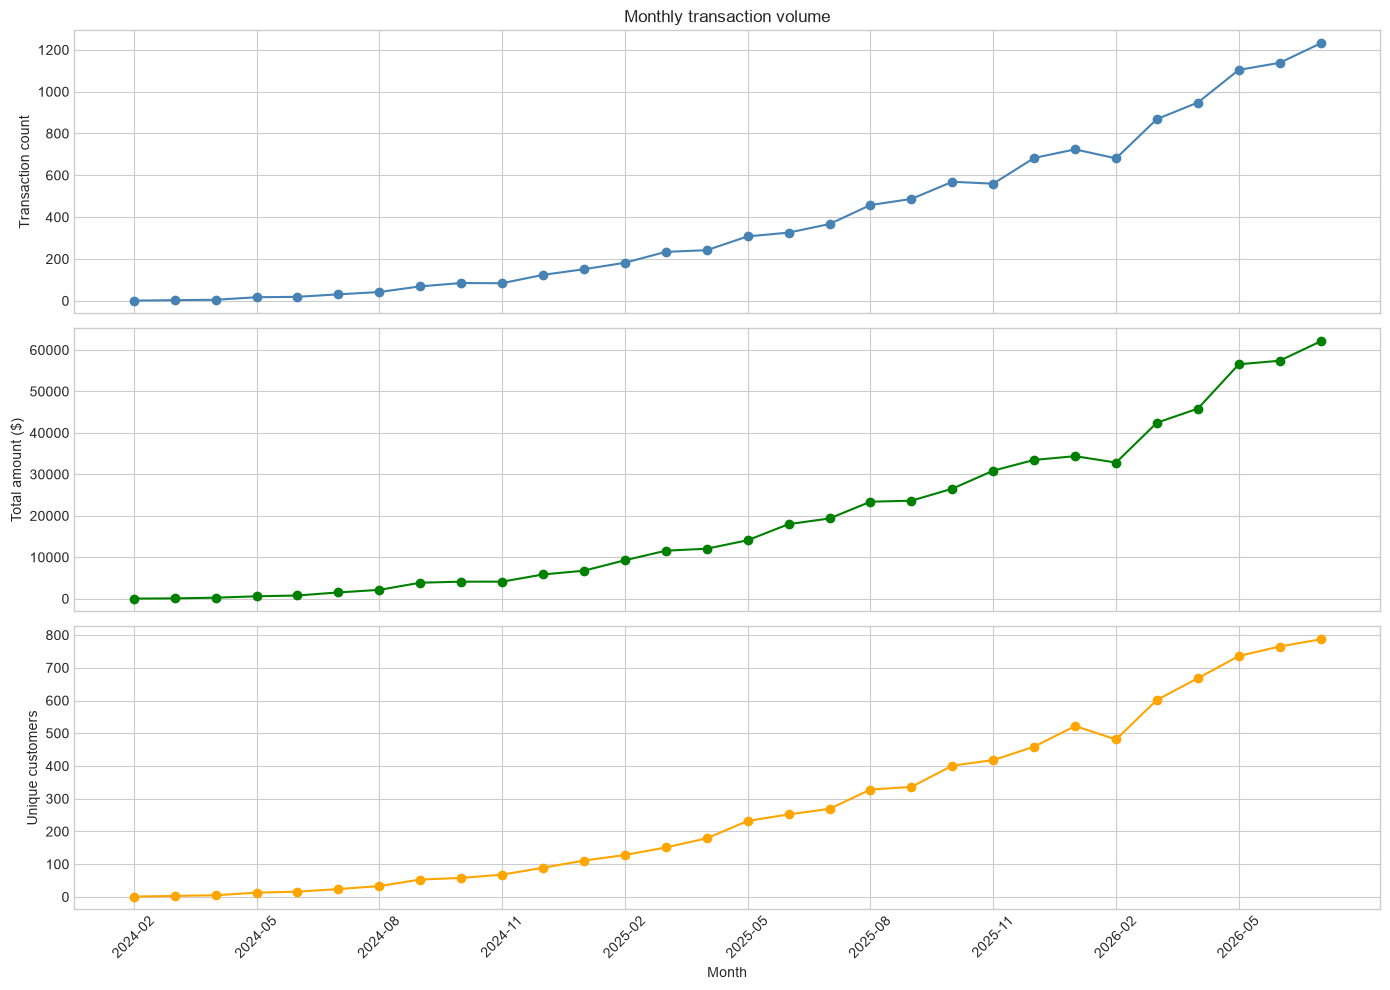

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
months_str = [r["txn_month"].strftime("%Y-%m") for _, r in monthly.iterrows()]

axes[0].plot(range(len(monthly)), monthly["txn_count"], marker="o", color="steelblue")
axes[0].set_ylabel("Transaction count")
axes[0].set_title("Monthly transaction volume")

axes[1].plot(range(len(monthly)), monthly["total_amount"], marker="o", color="green")
axes[1].set_ylabel("Total amount ($)")

axes[2].plot(range(len(monthly)), monthly["unique_customers"], marker="o", color="orange")
axes[2].set_ylabel("Unique customers")
axes[2].set_xlabel("Month")

for ax in axes:
    ax.set_xticks(range(0, len(monthly), 3))
    ax.set_xticklabels([months_str[i] for i in range(0, len(monthly), 3)], rotation=45)

plt.tight_layout()
plt.show()

## 7. Multi-source agreement

In [16]:
# Reaggregate row-level to customer x month
row_agg = txns.groupby(["customer_id", "txn_month"]).agg(
    txn_count=("amount", "count"),
    total_amount=("amount", "sum"),
    return_count=("is_returned", "sum")
).reset_index()

row_monthly = row_agg.groupby("txn_month").agg(
    row_txns=("txn_count", "sum"),
    row_amt=("total_amount", "sum"),
    row_cust=("customer_id", "nunique")
).reset_index()

parq_monthly = monthly_agg.groupby("txn_month").agg(
    parq_txns=("txn_count", "sum"),
    parq_amt=("total_amount", "sum"),
    parq_cust=("customer_id", "nunique")
).reset_index()

merged = row_monthly.merge(parq_monthly, on="txn_month", how="outer").fillna(0).sort_values("txn_month")
merged["match"] = merged["row_txns"] == merged["parq_txns"]

print(f"Months compared: {len(merged)}")
print(f"Exact match: {merged['match'].sum()} / {len(merged)}")
print(f"Diverged: {len(merged) - merged['match'].sum()}")

div = merged[~merged["match"]]
for _, r in div.iterrows():
    diff_pct = (r["row_txns"] - r["parq_txns"]) / r["parq_txns"] * 100
    print(f"\n  {r['txn_month'].strftime('%Y-%m')}:")
    print(f"    Row-level: {r['row_txns']} txns, ${r['row_amt']:.2f}, {r['row_cust']} cust")
    print(f"    Parquet:   {r['parq_txns']} txns, ${r['parq_amt']:.2f}, {r['parq_cust']} cust")
    print(f"    Gap:       {diff_pct:.1f}%")

Months compared: 30
Exact match: 29 / 30
Diverged: 1

  2026-07:
    Row-level: 1231 txns, $62084.62, 787 cust
    Parquet:   994 txns, $50116.67, 685 cust
    Gap:       23.8%


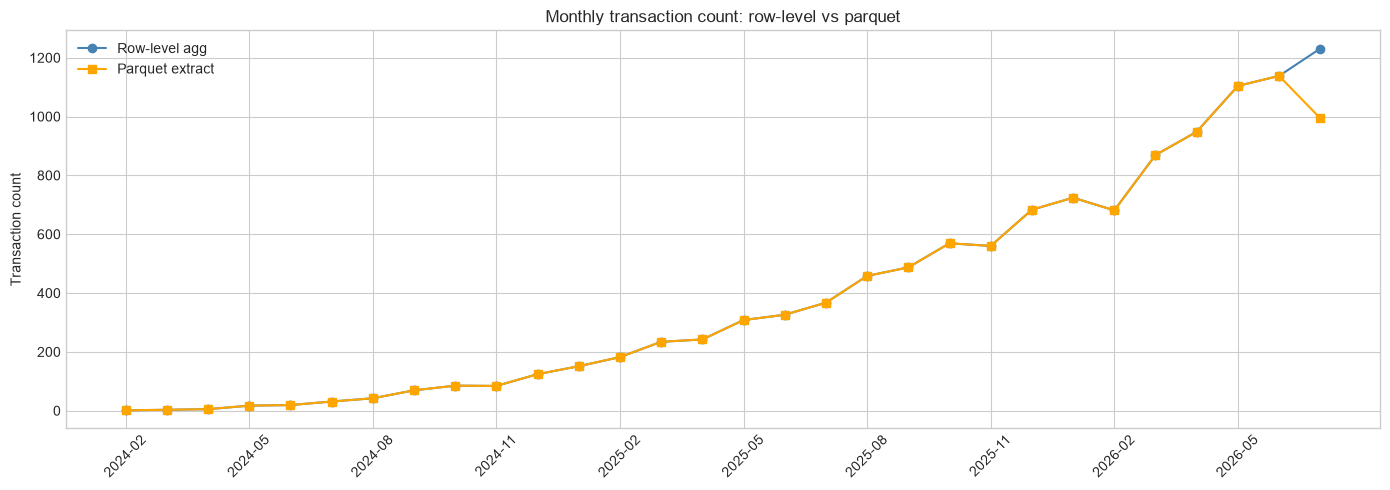

In [17]:
fig, ax = plt.subplots(figsize=(14, 5))
months = [m.strftime("%Y-%m") for m in merged["txn_month"]]
ax.plot(months, merged["row_txns"], marker="o", label="Row-level agg", color="steelblue")
ax.plot(months, merged["parq_txns"], marker="s", label="Parquet extract", color="orange")
ax.set_xticks(range(0, len(months), 3))
ax.set_xticklabels([months[i] for i in range(0, len(months), 3)], rotation=45)
ax.set_ylabel("Transaction count")
ax.set_title("Monthly transaction count: row-level vs parquet")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Summary

| Finding | Detail |
|---|---|
| **Churn rate** | 13.47% overall, 8.53% among active customers |
| **Zero-activity** | 81 customers, all churned — distinct segment, not missing data |
| **Amount distribution** | Heavily right-skewed (mean $49.72, median $33.82, max $1,684.21) |
| **Channel** | Not significant (p=0.12). Organic highest (15.27%), paid_search lowest (10.21%) |
| **Region** | Not significant (p=0.29). East highest (16.36%) |
| **Total amount** | Significant (p≈0), large effect. Non-churned spend more |
| **Return rate** | Significant (p≈0), small effect |
| **Days since last txn** | **Leakage-tainted** — circular with label definition |
| **Time trend** | Strongly upward (~1,231× growth over 30 months) |
| **Multi-source** | 29/30 months match; July 2026 cutoff anomaly (~24% gap) |

### Recommended model family
**Gradient-boosted decision trees (LightGBM/XGBoost)** — handles mixed types, skewed variables, imbalance, and nonlinear interactions.

### Key exclusions
- `days_since_last_transaction` — leakage-tainted
- Any trailing-90-day windowed features — same circularity

See `MODEL_RECOMMENDATION.md` and `DATA_ISSUES.md` for full details.